# Correlation function multipoles

This notebook computes the redshift-space correlation function multipoles of a galaxy sample and their derivatives with respect to the cosmological parameters.

Galaxy surveys measure clustering in redshift space, where peculiar velocities squash structures along the line of sight. In linear theory (Kaiser) a tracer with bias $b$ has the power spectrum multipoles:

$$
P_0 = \left(1 + \tfrac{2}{3} \beta + \tfrac{1}{5} \beta^2\right) b^2 P, \qquad
P_2 = \left(\tfrac{4}{3} \beta + \tfrac{4}{7} \beta^2\right) b^2 P, \qquad
P_4 = \tfrac{8}{35} \beta^2 b^2 P,
$$

with $\beta = f / b$ and $f = \mathrm{d} \ln \delta / \mathrm{d} \ln a$ the growth rate. The correlation function multipoles are their Hankel transforms:

$$
\xi_\ell(s) = \frac{i^\ell}{2 \pi^2} \int \mathrm{d}k \, k^2 P_\ell(k) \, j_\ell(k s) .
$$

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import spherical_jn

from discoeb import LCDM, solve_eb

REDSHIFT = 0.5
BIAS = 2.0
SMOOTHING = 1.0  # Gaussian damping of P(k), Mpc: makes the transform converge
K = np.geomspace(1.0e-4, 4.0, 192)  # wave numbers of the solve, 1/Mpc
K_FINE = np.geomspace(K[0], K[-1], 8192)  # of the transform: resolves j_l(k s)
S = np.linspace(20.0, 200.0, 91)  # separations, Mpc

We start from the Planck 2018 best fit and differentiate in $H_0$, $\Omega_m$, $\Omega_b$ and $n_s$:

In [2]:
h = 0.6732117
PLANCK = dict(
    Omega_m=(0.02238280 + 0.1201075) / h**2,
    Omega_b=0.02238280 / h**2,
    H_0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    T_cmb=2.7255,
    Y_He=0.2454006,
    N_eff=3.046,
)
PARAMETERS = {
    "H_0": "H_0",
    "Omega_m": r"\Omega_m",
    "Omega_b": r"\Omega_b",
    "n_s": "n_s",
}
theta = jnp.asarray([PLANCK[key] for key in PARAMETERS])

`solve_eb` integrates in the scale factor and differentiates at fixed scale factors.

In [3]:
A_SAMPLE = 1.0 / (1.0 + REDSHIFT)

The transform needs $j_0$, $j_2$ and $j_4$ on the grid of $k s$. The grid does not depend on the parameters, so we tabulate them once with `scipy.special.spherical_jn`.

In [4]:
BESSEL = {ell: spherical_jn(ell, K_FINE * S[:, None]) for ell in (0, 2, 4)}

`solve_eb` keeps the overdensities, the metric rate `h_prime`, the baryon velocity divergence `theta_b` and the expansion rate `aH`. In the synchronous gauge $\delta_c' = -h'/2$ and $\delta_b' = -\theta_b - h'/2$, so the growth rate is

$$
f = \frac{\delta'}{a H \, \delta} = -\frac{h'/2 + f_b \theta_b}{a H \, \delta},
$$

with $f_b = \omega_b / (\omega_c + \omega_b)$. The Hankel transform is a trapezoid rule in $\ln k$ on a fine grid.

In [5]:
def multipoles(theta):
    """``xi_0, xi_2, xi_4`` at the separations ``S``, ``(3, len(S))``."""

    cosmology = LCDM.from_density_parameters(
        **{**PLANCK, **dict(zip(PARAMETERS, theta))}
    )
    values = solve_eb(
        cosmology,
        K,
        [A_SAMPLE],
        keep=("delta_c", "delta_b", "h_prime", "theta_b", "aH"),
    )
    delta_c, delta_b, h_prime, theta_b, aH = values[
        0, :, :, 0
    ]  # each (k,), at the redshift

    f_b = cosmology.omega_b / (cosmology.omega_c + cosmology.omega_b)
    delta = (1.0 - f_b) * delta_c + f_b * delta_b
    growth_rate = -(0.5 * h_prime + f_b * theta_b) / (aH * delta)
    primordial = cosmology.A_s * (K / cosmology.k_p) ** (cosmology.n_s - 1.0)
    pk = 2.0 * jnp.pi**2 / K**3 * primordial * delta**2

    beta = growth_rate / BIAS
    kaiser = (
        1.0 + 2.0 / 3.0 * beta + beta**2 / 5.0,
        4.0 / 3.0 * beta + 4.0 / 7.0 * beta**2,
        8.0 / 35.0 * beta**2,
    )
    xi = []
    for ell, sign, factor in zip((0, 2, 4), (1.0, -1.0, 1.0), kaiser):
        log_p = jnp.interp(np.log(K_FINE), np.log(K), jnp.log(BIAS**2 * factor * pk))
        integrand = K_FINE**3 * jnp.exp(log_p - (K_FINE * SMOOTHING) ** 2)
        integral = jnp.trapezoid(integrand * BESSEL[ell], np.log(K_FINE), axis=-1)
        xi.append(sign * integral / (2.0 * jnp.pi**2))
    return jnp.stack(xi)

One GPU launch returns both the power spectrum multipoles and their derivatives. `jax.jacfwd` integrates a sensitivity column per parameter beside the solve, and `has_aux=True` returns the multipoles of that same solve:

In [6]:
def with_value(theta):
    xi = multipoles(theta)
    return xi, xi  # differentiated, and returned as it is


dxi, xi = jax.jacfwd(with_value, has_aux=True)(theta)
dxi, xi = np.asarray(dxi), np.asarray(xi)  # (multipole, s, parameter), (multipole, s)

In [7]:
print(f"z = {REDSHIFT}, b = {BIAS}")
print(f"{'s [Mpc]':>8}  {'s^2 xi_0':>10}  {'s^2 xi_2':>10}  {'s^2 xi_4':>10}")
for i in range(0, len(S), 10):
    print(f"{S[i]:8.0f}" + "".join(f"  {v:10.3f}" for v in S[i] ** 2 * xi[:, i]))
peak = (S > 120.0) & (S < 180.0)
print(f"BAO peak of xi_0 at s = {S[peak][np.argmax(xi[0, peak])]:.0f} Mpc")

z = 0.5, b = 2.0
 s [Mpc]    s^2 xi_0    s^2 xi_2    s^2 xi_4
      20     256.208    -123.180       5.416
      40     230.879    -186.993      10.135
      60     172.103    -209.025      12.958
      80     118.548    -211.439      14.542
     100      74.809    -204.819      15.330
     120      37.567    -194.833      15.604
     140      79.879    -153.970      16.707
     160      89.420    -143.759      14.927
     180      -3.358    -171.956      12.771
     200     -40.702    -168.504      12.989
BAO peak of xi_0 at s = 148 Mpc


The $H_0$ panel shows how the BAO peak moves with the Hubble constant.

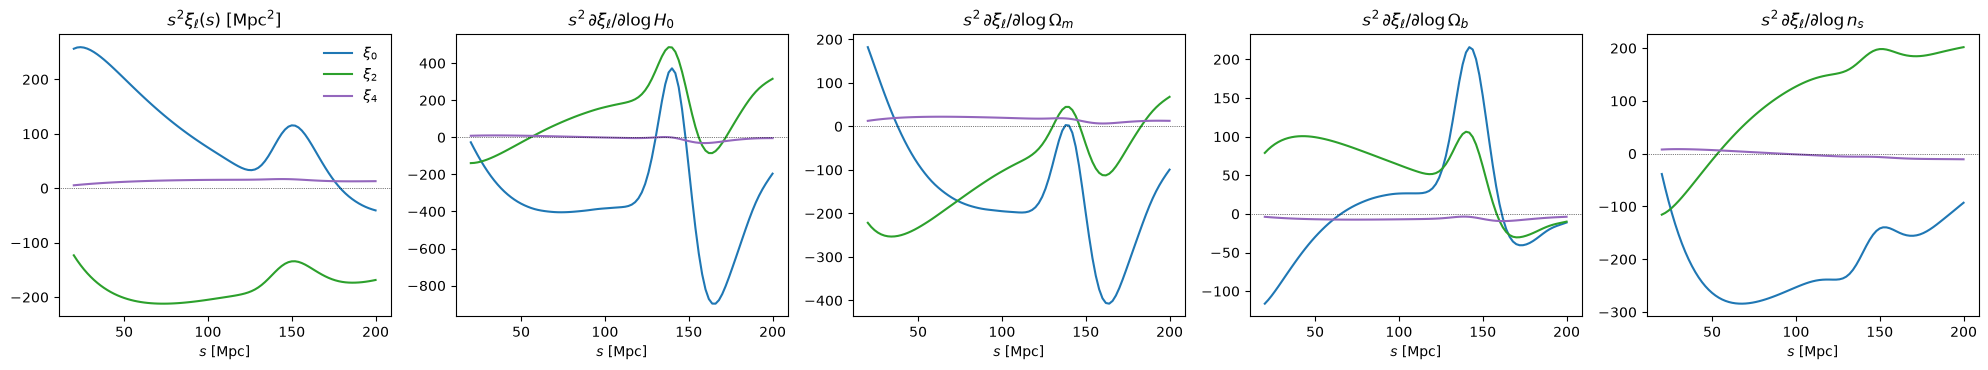

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), sharex=True)
styles = (("C0", r"$\xi_0$"), ("C2", r"$\xi_2$"), ("C4", r"$\xi_4$"))
for ell, (color, label) in enumerate(styles):
    axes[0].plot(S, S**2 * xi[ell], color=color, label=label)
    for i, ax in enumerate(axes[1:]):
        ax.plot(S, S**2 * theta[i] * dxi[ell, :, i], color=color)
axes[0].set_title(r"$s^2 \xi_\ell(s)$ [Mpc$^2$]")
axes[0].legend(frameon=False)
for ax, label in zip(axes[1:], PARAMETERS.values()):
    ax.set_title(rf"$s^2\, \partial \xi_\ell / \partial \log {label}$")
for ax in axes:
    ax.axhline(0.0, color="k", lw=0.5, ls=":")
    ax.set_xlabel(r"$s$ [Mpc]")
fig.tight_layout()
plt.show()